In [1]:
# --- arranque en Colab (no hace nada fuera de Colab) -----------------------
# Colab arranca en /content con un entorno vacío: sin esta celda el
# `import environment` siguiente falla con ModuleNotFoundError. Generada por
# tools/py_to_notebook.py -- editala ahí, no acá.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/solidgoldmagickarp/proyecto_de_lenguaje_emergente.git"
    REPO_DIR = "proyecto_de_lenguaje_emergente"

    # El orden de las guardas importa: primero probar DÓNDE estamos, después qué hay en disco.
    # `isdir(REPO_DIR)` es relativo, así que chequearlo primero clonaría una copia
    # anidada en cualquier re-ejecución de esta celda dentro de la misma sesión (algo rutinario).
    if os.path.basename(os.getcwd()) != REPO_DIR:
        if not os.path.isdir(REPO_DIR):
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
        os.chdir(REPO_DIR)
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True
    )

    # El disco de Colab es EFÍMERO: cada checkpoint se pierde cuando el entorno de ejecución
    # se desconecta (~90 min de inactividad en el plan gratuito), y las Etapas 3, 4 y 5 necesitan
    # todas los checkpoints de la Etapa 2. Descomentá para guardarlos en Drive en su lugar.
    #
    # Notar `islink`, no `exists`: importar `environment` crea un directorio checkpoints/
    # REAL, y `exists` entonces saltearía el enlace en silencio y mandaría cada
    # checkpoint de vuelta al disco efímero.
    #
    # from google.colab import drive
    # drive.mount("/content/drive")
    # PERSISTENT = "/content/drive/MyDrive/proyecto_de_lenguaje_emergente/checkpoints"
    # os.makedirs(PERSISTENT, exist_ok=True)
    # if os.path.islink("checkpoints"):
    #     print("checkpoints ->", os.readlink("checkpoints"))
    # elif os.path.isdir("checkpoints"):
    #     print("ADVERTENCIA: checkpoints/ ya es un directorio real, así que NO está en Drive.")
    #     print("Mové su contenido a", PERSISTENT, ", borralo, y volvé a ejecutar esta celda.")
    # else:
    #     os.symlink(PERSISTENT, "checkpoints")
    #     print("checkpoints ->", PERSISTENT)

    print("Arranque en Colab OK. Directorio de trabajo:", os.getcwd())

# Etapa 2 · Preentrenamiento y ablación ancho contra profundidad

El mismo Transformer decoder-only de clase (`lab.py`), con `vocab_size` igual al BPE de la Etapa 1, entrenado
sobre TinyStories. Dos modelos con cantidad de parámetros parecida: **ancho** (`n_embd=256`, `n_layer=2`) y
**profundo** (`n_embd=192`, `n_layer=5`). Todo lo demás queda fijo: datos, orden de los batches, pasos, `lr`,
semilla, `block_size`, `n_head`.

Escribe `checkpoints/pretrain_step0.pt`, `pretrain_wide.pt`, `pretrain_deep.pt` y los historiales en JSON.

In [2]:
import environment  # noqa: F401

environment.summary()

SMOKE_TEST = False  # True: ~200 pasos sobre un subconjunto mínimo, solo para ver que el código corre.
RETRAIN = False    # False: si el checkpoint ya existe (p. ej. en Drive), se carga en vez de reentrenar.
SEED = 1337

DEVICE = environment.device()
PRETRAIN_STORIES = 5_000 if SMOKE_TEST else 500_000
VAL_STORIES = 1_000 if SMOKE_TEST else 10_000

BLOCK_SIZE = 192
N_HEAD = 8
DROPOUT = 0.1
BATCH_SIZE = 16 if SMOKE_TEST else 64
MAX_STEPS = 200 if SMOKE_TEST else 6_000
LR = 3e-4
EVAL_INTERVAL = 50 if SMOKE_TEST else 250
EVAL_ITERS = 10 if SMOKE_TEST else 50
SAMPLE_STEPS = (0, 50, 100, 200) if SMOKE_TEST else (0, 250, 500, 1000, 1500, 2000, 3000, 4500, 6000)

ENTORNO
os             : Windows 11
python         : 3.13.15
venv           : C:\dev\ia-generativa-sistemas-multiagente\tp\1\proyecto_de_lenguaje_emergente\.venv
cpu            : Intel64 Family 6 Model 158 Stepping 10, GenuineIntel
logical_cores  : 6
torch          : 2.11.0+cu128
torch_threads  : 6
cuda_available : True
gpu            : NVIDIA GeForce RTX 3050
gpu_memory_gb  : 6.44
ram_total_gb   : 17.1
ram_free_gb    : 5.7
--------------------------------------------------------------
HF_HOME        : C:\Users\juani\.cache\huggingface
ca_bundle      : no presente (normal)


## Tokenizar el corpus

Se tokeniza una vez y se cachea en `checkpoints/` como `uint16`. Los dos modelos de la ablación leen exactamente
los mismos arreglos.

In [3]:
import json
from pathlib import Path

import numpy as np
import torch
from tokenizers import Tokenizer

from data import load_tinystories
from lab import EOS_TOKEN, encode_texts

tokenizer = Tokenizer.from_file("checkpoints/tokenizer.json")
VOCAB_SIZE = tokenizer.get_vocab_size()
EOS_ID = tokenizer.token_to_id(EOS_TOKEN)

cache = Path(f"checkpoints/tokens_{'smoke' if SMOKE_TEST else 'full'}.npz")
if cache.exists():
    arrays = np.load(cache)
    train_data, val_data, story_lengths = arrays["train"], arrays["val"], arrays["val_story_lengths"]
    print(f"tokens cargados de {cache}")
else:
    train_texts = load_tinystories("train", limit=PRETRAIN_STORIES)["text"]
    val_texts = load_tinystories("validation", limit=VAL_STORIES)["text"]
    train_data = encode_texts(tokenizer, train_texts, EOS_ID)
    val_data = encode_texts(tokenizer, val_texts, EOS_ID)
    story_lengths = np.array([len(e.ids) + 1 for e in tokenizer.encode_batch(list(val_texts))])
    np.savez(cache, train=train_data, val=val_data, val_story_lengths=story_lengths)
    print(f"tokens guardados en {cache}")

print(f"train: {len(train_data):,} tokens | val: {len(val_data):,} tokens | V = {VOCAB_SIZE:,}")

tokens guardados en checkpoints\tokens_full.npz
train: 110,604,636 tokens | val: 2,011,410 tokens | V = 8,192


In [4]:
# ¿Cuánto de un cuento entra en la ventana? (el `block_size` se eligió mirando esto)
for b in (128, 192, 256):
    print(f"block_size {b:>3}: {np.mean(story_lengths <= b):6.1%} de los cuentos de validación entran enteros")
print(f"tokens por cuento: media {story_lengths.mean():.0f}, mediana {np.median(story_lengths):.0f}, "
      f"p90 {np.percentile(story_lengths, 90):.0f}")

block_size 128:   5.9% de los cuentos de validación entran enteros
block_size 192:  58.7% de los cuentos de validación entran enteros
block_size 256:  88.8% de los cuentos de validación entran enteros
tokens por cuento: media 201, mediana 183, p90 266


## Contar parámetros antes de entrenar

Si los dos modelos difieren mucho en tamaño, la ablación deja de ser ancho contra profundo y pasa a ser grande
contra chico.

In [5]:
from lab import GPTConfig, GPTLanguageModel, count_params

CONFIGS = {
    "wide": GPTConfig(vocab_size=VOCAB_SIZE, n_embd=256, n_layer=2, n_head=N_HEAD, block_size=BLOCK_SIZE, dropout=DROPOUT),
    "deep": GPTConfig(vocab_size=VOCAB_SIZE, n_embd=192, n_layer=5, n_head=N_HEAD, block_size=BLOCK_SIZE, dropout=DROPOUT),
}

param_counts = {name: count_params(GPTLanguageModel(cfg)) for name, cfg in CONFIGS.items()}
keys = list(param_counts["wide"])
print(f"{'componente':<20} {'wide':>12} {'deep':>12}")
for k in keys:
    print(f"{k:<20} {param_counts['wide'][k]:>12,} {param_counts['deep'][k]:>12,}")
w, d = param_counts["wide"]["total"], param_counts["deep"]["total"]
print(f"\ndiferencia total: {abs(w - d) / max(w, d):.1%}")
for name, pc in param_counts.items():
    print(f"{name}: {(pc['token_embedding'] + pc['lm_head']) / pc['total']:.0%} del modelo es embedding + lm_head; "
          f"{pc['blocks'] / pc['total']:.0%} son los bloques")

componente                   wide         deep
token_embedding         2,097,152    1,572,864
position_embedding         49,152       36,864
blocks                  1,577,984    2,221,440
ln_f                          512          384
lm_head                 2,105,344    1,581,056
total                   5,830,144    5,412,608

diferencia total: 7.2%
wide: 72% del modelo es embedding + lm_head; 27% son los bloques
deep: 58% del modelo es embedding + lm_head; 41% son los bloques


In [6]:
# Chinchilla (Hoffmann et al., 2022): ~20 tokens por parámetro es el óptimo de cómputo.
tokens_seen = MAX_STEPS * BATCH_SIZE * BLOCK_SIZE
for name, pc in param_counts.items():
    optimal = 20 * pc["total"]
    print(f"{name}: verá {tokens_seen / 1e6:.1f}M tokens ({tokens_seen / len(train_data):.2f} épocas); "
          f"Chinchilla sugiere ~{optimal / 1e6:.0f}M -> {tokens_seen / optimal:.0%} del óptimo")

wide: verá 73.7M tokens (0.67 épocas); Chinchilla sugiere ~117M -> 63% del óptimo
deep: verá 73.7M tokens (0.67 épocas); Chinchilla sugiere ~108M -> 68% del óptimo


## Prompts de prueba

Diseñados antes de entrenar y fijos para los dos modelos.

- **Recuerdo** (greedy): completar un dato común. Además de la completación, se mide el *rango* de la palabra
  esperada en la distribución del próximo token y su probabilidad: un número por prompt, sin depender de leer.
- **Contexto**: un cuento que introduce un nombre y un objeto, seguido de `k` oraciones de relleno, y una
  oración que termina justo antes de donde el nombre debería reaparecer. Se mide `log p(nombre correcto) −
  log p(nombre distractor)`, y se promedia con los nombres intercambiados para cancelar la preferencia a priori
  del modelo por uno u otro nombre. Variar `k` estira la distancia: es la pregunta de largo alcance.

In [7]:
import math

RECALL_PROMPTS = [
    ("The sun is very", [" hot", " bright", " big"]),
    ("The sky was", [" blue"]),
    ("The grass is", [" green"]),
    ("At night, you can see the moon and the", [" stars"]),
    ("The fish swims in the", [" water", " pond", " sea", " ocean", " river", " lake"]),
    ("A cow says", [" moo", ' "', " \""]),
    ("Birds can fly in the", [" sky"]),
    ("When it rains, the ground gets", [" wet"]),
    ("Tom was hungry, so he ate an", [" apple"]),
    ("She put on her shoes and her", [" coat", " hat", " dress", " socks", " jacket"]),
    ("In winter, it is cold and there is", [" snow"]),
    ("The dog wagged its", [" tail"]),
]

FILLER = [
    "The sun was shining and the birds were singing.",
    "They walked past a big tree with green leaves.",
    "A little dog ran by and barked happily.",
    "The wind was soft and the flowers smelled nice.",
    "They saw a pond with ducks swimming in it.",
    "Some kids were playing on the swings.",
]
NAME_PAIRS = [("Lily", "Max"), ("Ben", "Sue"), ("Mia", "Tom")]
OBJECT_PAIRS = [("ball", "kite"), ("teddy bear", "red car")]
CONTEXT_DISTANCES = [0, 2, 4, 6]


def context_prompts(name, obj, k):
    story = (f"Once upon a time, there was a kid named {name}. {name} had a {obj}. "
             f"One day, {name} went to the park with Mom. " + " ".join(FILLER[:k]))
    return {
        "name": story + " After a long day, Mom smiled and said, \"Time to go home,",
        "object": story + f" When they got home, {name} put the",
    }


def next_token_logprobs(model, prompt):
    ids = tokenizer.encode(prompt).ids
    x = torch.tensor([ids[-model.config.block_size:]], device=DEVICE)
    with torch.no_grad():
        logits, _ = model(x)
    return torch.log_softmax(logits[0, -1].float(), dim=-1)


def first_id(text):
    return tokenizer.encode(text).ids[0]


def run_probes(model):
    from lab import generate_text

    recall = []
    for prompt, targets in RECALL_PROMPTS:
        lp = next_token_logprobs(model, prompt)
        ranks = (lp.argsort(descending=True) == torch.tensor([first_id(t) for t in targets], device=DEVICE)[:, None])
        best_rank = int(ranks.float().argmax(dim=1).min().item()) + 1
        prob = float(sum(lp[first_id(t)].exp().item() for t in targets))
        completion = generate_text(model, tokenizer, prompt, max_new_tokens=6, greedy=True, stop_at_eos=True)
        recall.append({"prompt": prompt, "targets": targets, "best_rank": best_rank, "target_prob": prob,
                       "greedy": completion})

    context = {"name": {k: [] for k in CONTEXT_DISTANCES}, "object": {k: [] for k in CONTEXT_DISTANCES}}
    for k in CONTEXT_DISTANCES:
        for kind, pairs in (("name", NAME_PAIRS), ("object", OBJECT_PAIRS)):
            for a, b in pairs:
                margins = []
                for correct, wrong in ((a, b), (b, a)):
                    # nombre: slot " <name>"; objeto: slot " <obj>" (primer token de la palabra)
                    obj_for_story = OBJECT_PAIRS[0][0] if kind == "name" else correct
                    name_for_story = correct if kind == "name" else NAME_PAIRS[0][0]
                    prompt = context_prompts(name_for_story, obj_for_story, k)[kind]
                    lp = next_token_logprobs(model, prompt)
                    margins.append(float(lp[first_id(" " + correct)] - lp[first_id(" " + wrong)]))
                context[kind][k].append(float(np.mean(margins)))
    context_summary = {kind: {k: float(np.mean(v)) for k, v in by_k.items()} for kind, by_k in context.items()}
    return {"recall": recall, "context": context_summary}


def print_probes(res, label):
    print(f"=== {label} ===")
    print(f"{'prompt':<42} {'rango':>5} {'p(obj)':>7}  greedy")
    for r in res["recall"]:
        print(f"{r['prompt'][:42]:<42} {r['best_rank']:>5} {r['target_prob']:>7.3f}  {r['greedy']!r}")
    ranks = [r["best_rank"] for r in res["recall"]]
    print(f"recuerdo: top-1 {np.mean([x == 1 for x in ranks]):.0%} | top-5 {np.mean([x <= 5 for x in ranks]):.0%} "
          f"| prob media {np.mean([r['target_prob'] for r in res['recall']]):.3f}")
    for kind in ("name", "object"):
        row = " ".join(f"k={k}: {v:+.2f}" for k, v in res["context"][kind].items())
        print(f"contexto [{kind}] margen log-prob (>0 = prefiere el correcto): {row}")

## Entrenar

Para cada modelo: semilla fija, se guarda el paso 0 (sin entrenar), se entrena, y se leen muestras en varios
puntos. Las muestras usan una semilla distinta por prompt (`SEED + i`) y la misma entre modelos.

In [8]:
from lab import generate_text, load_checkpoint, save_checkpoint, train

SAMPLE_PROMPTS = ["Once upon a time", "Lily and her mom went to the", "Tom found a big box. Inside the box"]


def train_or_load(name):
    path = Path(f"checkpoints/pretrain_{name}.pt")
    hist_path = Path(f"checkpoints/pretrain_{name}_history.json")
    if path.exists() and hist_path.exists() and not RETRAIN:
        model, _ = load_checkpoint(path, DEVICE)
        saved = json.loads(hist_path.read_text(encoding="utf-8"))
        print(f"{name}: cargado de {path}")
        return model, saved["history"], saved["samples"]

    torch.manual_seed(SEED)
    model = GPTLanguageModel(CONFIGS[name]).to(DEVICE)
    if name == "wide":
        save_checkpoint("checkpoints/pretrain_step0.pt", model, step=0, seed=SEED)

    samples = {}

    def sample_fn(step):
        samples[step] = [generate_text(model, tokenizer, p, max_new_tokens=100, seed=SEED + i)
                         for i, p in enumerate(SAMPLE_PROMPTS)]
        print(f"--- muestra paso {step}: {samples[step][0][:200]!r}")

    history = train(
        model, train_data, val_data, device=DEVICE, max_steps=MAX_STEPS, batch_size=BATCH_SIZE, lr=LR,
        eval_interval=EVAL_INTERVAL, eval_iters=EVAL_ITERS, sample_steps=SAMPLE_STEPS, sample_fn=sample_fn,
        seed=SEED,
    )
    save_checkpoint(path, model, step=MAX_STEPS, seed=SEED, smoke_test=SMOKE_TEST)
    hist_path.write_text(json.dumps({"history": history, "samples": samples}, ensure_ascii=False, indent=1),
                         encoding="utf-8")
    return model, history, {str(k): v for k, v in samples.items()}


models_, histories, samples = {}, {}, {}
for name in CONFIGS:
    models_[name], histories[name], samples[name] = train_or_load(name)
    print(f"{name}: {histories[name]['elapsed_s'][-1] / 60:.1f} min, pico de memoria "
          f"{histories[name]['peak_mem_mb']:.0f} MB\n")

checkpoint guardado: checkpoints\pretrain_step0.pt (23.3 MB)


paso      0 | train 9.0552 | val 9.0554 | ppl val  8564.79 | lr 3.00e-06 |      5s


--- muestra paso 0: ' let batteries grabs Pam supp follows poppy vend kept seeker veterinarianween zooming displayedomed opening recording town alowed clos winigail� garage weeke CarlLeo from Wally talks pig strength sail'


paso    250 | train 3.9422 | val 3.9498 | ppl val    51.92 | lr 3.00e-04 |     45s


--- muestra paso 250: ', there was a little girl named Lily. She was a little girl named Lily. Lily. She was a little boy named Lily. Max. She was sad and her mom and Lily.\n\n\n\nShe said, "You can be a great day, "I love you.'


paso    500 | train 3.4123 | val 3.4285 | ppl val    30.83 | lr 2.97e-04 |     86s


... (59 outputs left out)

paso   5500 | train 2.3360 | val 2.3604 | ppl val    10.59 | lr 3.48e-05 |   1553s


paso   5750 | train 2.3308 | val 2.3556 | ppl val    10.54 | lr 3.12e-05 |   1621s


paso   6000 | train 2.3262 | val 2.3511 | ppl val    10.50 | lr 3.00e-05 |   1688s


--- muestra paso 6000: ", there was a little girl named Lily. She loved to eat yummy pie, but her mommy told her to come and eat dinner. But Lily didn't want to want to eat, so she asked her mommy to come back. Her mommy sai"
checkpoint guardado: checkpoints\pretrain_deep.pt (21.7 MB)
deep: 28.1 min, pico de memoria 3279 MB



## Curvas de pérdida y perplejidad

Línea punteada: `ln(V)`, la pérdida de adivinar uniformemente sobre el vocabulario.

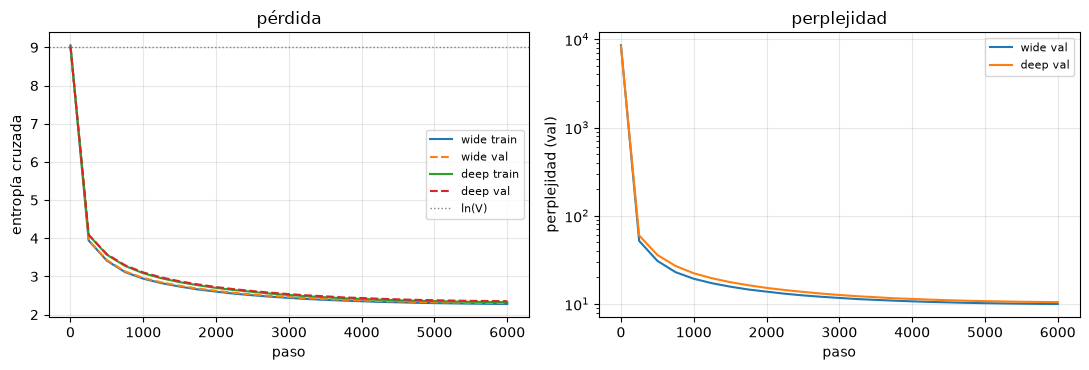

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, h in histories.items():
    axes[0].plot(h["step"], h["train_loss"], label=f"{name} train")
    axes[0].plot(h["step"], h["val_loss"], "--", label=f"{name} val")
    axes[1].plot(h["step"], [math.exp(v) for v in h["val_loss"]], label=f"{name} val")
axes[0].axhline(math.log(VOCAB_SIZE), color="gray", ls=":", lw=1, label="ln(V)")
axes[0].set(xlabel="paso", ylabel="entropía cruzada", title="pérdida")
axes[1].set(xlabel="paso", ylabel="perplejidad (val)", title="perplejidad", yscale="log")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("checkpoints/stage2_loss_curves.png", dpi=110)
plt.show()

## Muestras a lo largo del entrenamiento

Junto a cada muestra, la pérdida de validación en ese paso (o la evaluación más cercana).

In [10]:
for name in CONFIGS:
    h = histories[name]
    print(f"\n{'=' * 30} {name} {'=' * 30}")
    for step_key in sorted(samples[name], key=int):
        step = int(step_key)
        j = int(np.argmin([abs(s - step) for s in h["step"]]))
        print(f"\n[paso {step} | val loss ≈ {h['val_loss'][j]:.2f}]")
        for prompt, text in zip(SAMPLE_PROMPTS, samples[name][step_key]):
            print(f"  {prompt!r} -> {text!r}")


============================== wide ==============================

[paso 0 | val loss ≈ 9.06]
  'Once upon a time' -> ' let batteries grabs Pam supp follows poppy vend kept seeker veterinarianween zooming displayedomed opening recording town alowed clos winigail� garage weeke CarlLeo from Wally talks pig strength sails rocks lizard mill persist apblDave town closber mission mu goodbyes HelpcessJoe TommyLike Fo corners ears yummyHowSad vehicles tear Luna shakesitc decorated enthusiastic spring townongo widamusing fingers hardittle lun back supported Scccer explorers cleaned expect empty butter plays unif deer fork potatoes held advent sip sister alive thuhtray K humming safely respect'
  'Lily and her mom went to the' -> " anywhere.' scram� short trophyOur opening SadListen use clapping skirt Bet Princess TunaomedBenny.' getsfit pumpkins tiptoed seedolog printerighingBella Nut daisies streamile bank miss restaurant Thatâ crossing wantInsidehere sharing foxromise kissed wedding forksay

## Ablación: tabla y prompts de prueba

In [11]:
probe_results = {}
for name, model in models_.items():
    probe_results[name] = run_probes(model)
    print_probes(probe_results[name], name)
    print()

=== wide ===
prompt                                     rango  p(obj)  greedy
The sun is very                                1   0.256  ' hot and cold. It is'
The sky was                                    3   0.064  ' so bright and the sky was'
The grass is                                   2   0.041  ' blue and green. It has'
At night, you can see the moon and the         2   0.155  ' moon. It is very pretty'
The fish swims in the                          1   0.730  ' water. The fish swam closer'
A cow says                                     4   0.084  ', "Hello, cat.'
Birds can fly in the                           1   0.681  ' sky. He was so excited'
When it rains, the ground gets                 1   0.154  ' wet. It makes a loud'
Tom was hungry, so he ate an                   1   0.780  ' apple. He ate it all'
She put on her shoes and her                   2   0.083  ' shoes. She was very happy'
In winter, it is cold and there is             5   0.019  ' a big storm. The storm'
Th

=== deep ===
prompt                                     rango  p(obj)  greedy
The sun is very                                1   0.191  ' hot and cold.\n\n'
The sky was                                   13   0.012  ' so big and bright and beautiful'
The grass is                                  21   0.011  ' soft and soft.\n\n'
At night, you can see the moon and the         2   0.200  ' moon. It is very pretty'
The fish swims in the                          1   0.630  ' water and the fish. They'
A cow says                                     3   0.065  ', "I am a princess'
Birds can fly in the                           1   0.560  ' sky. He was so happy'
When it rains, the ground gets                 2   0.100  ' dark and cold. The sun'
Tom was hungry, so he ate an                   1   0.489  ' apple. He ate it all'
She put on her shoes and her                   2   0.133  ' shoes. She put on her'
In winter, it is cold and there is            23   0.005  ' no water. It is cold'
The dog

      modelo |       n_embd |      n_layer |       params | params_sin_emb |   train_loss |     val_loss |      val_ppl |  recall_top1 |  recall_top5 |  ctx_name_k0 |  ctx_name_k2 |  ctx_name_k4 |  ctx_name_k6 |   ctx_obj_k0 |   ctx_obj_k2 |   ctx_obj_k4 |   ctx_obj_k6 |      minutos |  pico_mem_MB
        wide |          256 |            2 |    5,830,144 |    1,577,984 |        2.278 |        2.302 |        9.992 |        0.500 |        1.000 |        7.395 |        7.290 |        7.313 |        7.040 |        4.826 |        3.313 |        2.875 |        1.810 |       15.503 |    2,243.829
        deep |          192 |            5 |    5,412,608 |    2,221,440 |        2.326 |        2.351 |       10.498 |        0.417 |        0.750 |        7.553 |        7.445 |        7.400 |        7.186 |        4.407 |        3.205 |        2.715 |        1.428 |       28.125 |    3,278.518


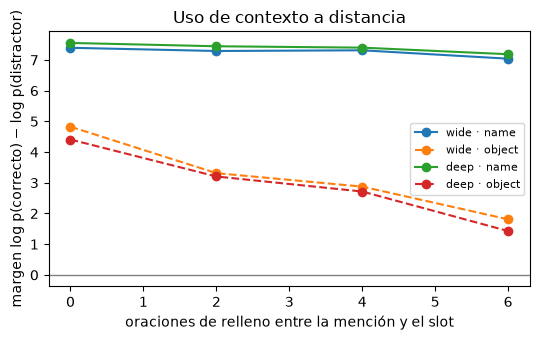

In [12]:
rows = []
for name in CONFIGS:
    h, pr = histories[name], probe_results[name]
    ranks = [r["best_rank"] for r in pr["recall"]]
    rows.append({
        "modelo": name,
        "n_embd": CONFIGS[name].n_embd,
        "n_layer": CONFIGS[name].n_layer,
        "params": param_counts[name]["total"],
        "params_sin_emb": param_counts[name]["blocks"],
        "train_loss": h["train_loss"][-1],
        "val_loss": h["val_loss"][-1],
        "val_ppl": math.exp(h["val_loss"][-1]),
        "recall_top1": float(np.mean([r == 1 for r in ranks])),
        "recall_top5": float(np.mean([r <= 5 for r in ranks])),
        **{f"ctx_name_k{k}": v for k, v in pr["context"]["name"].items()},
        **{f"ctx_obj_k{k}": v for k, v in pr["context"]["object"].items()},
        "minutos": h["elapsed_s"][-1] / 60,
        "pico_mem_MB": h["peak_mem_mb"],
    })

cols = list(rows[0])
print(" | ".join(f"{c:>12}" for c in cols))
for r in rows:
    print(" | ".join(f"{v:>12,.3f}" if isinstance(v, float) else f"{v:>12,}" if isinstance(v, int) else f"{v:>12}"
                     for v in r.values()))

with open("checkpoints/stage2_ablation.json", "w", encoding="utf-8") as f:
    json.dump({"rows": rows, "probes": probe_results, "smoke_test": SMOKE_TEST}, f, ensure_ascii=False, indent=1)

fig, ax = plt.subplots(figsize=(5.5, 3.5))
for name in CONFIGS:
    for kind, ls in (("name", "-"), ("object", "--")):
        ctx = probe_results[name]["context"][kind]
        ax.plot(list(ctx), list(ctx.values()), ls, marker="o", label=f"{name} · {kind}")
ax.axhline(0, color="gray", lw=1)
ax.set(xlabel="oraciones de relleno entre la mención y el slot", ylabel="margen log p(correcto) − log p(distractor)",
       title="Uso de contexto a distancia")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("checkpoints/stage2_context_probe.png", dpi=110)
plt.show()

## Para el informe

- ¿En qué rango de pérdida el texto deja de ser ruido y empieza a tener estructura de oración? ¿Cuándo aparece
  (si aparece) la consistencia a lo largo de un cuento?
- ¿Su par ancho/profundo reproduce lo que encontró el paper (ancho↔conocimiento, profundidad↔contexto)? Si no,
  ¿cuál es la mejor explicación: escala, cuánto entrenaron, cómo están diseñados los prompts? Tengan en cuenta
  que la diferencia entre dos prompts sueltos puede ser ruido: ¿con cuántos prompts les alcanzaría para
  afirmarlo?
- ¿Qué recortaron para que esto entrara en la máquina, y qué habrían medido con más?